# **Ödev 1 — EDA ve Baseline**

**MAP – Charting Student Math Misunderstandings** · CENG313 · GROUP32

Veri, Eedi platformundaki öğrencilerin çoktan seçmeli matematik sorularına verdikleri cevaplardan ve açıklamalardan oluşuyor. Soru metinleri görsellerden OCR ile çıkarılmış. Amaç, öğrencinin açıklamasından `Category:Misconception` etiketini tahmin etmek.

# **1- EDA**

##**Soru 1: Veride eksik değer var mı?**


In [21]:
# Colab'ın veri dosyalarını okuyabilmesi için Drive'a bağla
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA = '/content/drive/MyDrive/GROUP32_CENG313/data/'

# Veriyi pandas kütüphanesinin varsayılan ayarlarıyla oku
train = pd.read_csv(DATA + 'train.csv')
print(train.shape)

# Her kolondaki eksik değer sayısı
train.isna().sum()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(36696, 7)


,0
row_id,0
QuestionId,0
QuestionText,0
MC_Answer,0
StudentExplanation,0
Category,0
Misconception,26836


In [22]:
pd.crosstab(train["Category"].str.endswith("Misconception"),
            train["Misconception"].isna(),
            rownames=["Category yanılgı içeriyor"],
            colnames=["Misconception boş"])

Misconception boş,False,True
Category yanılgı içeriyor,,
False,0,26836
True,9860,0


### **Bulgu:** Kaggle'ın veri açıklamasına göre bu hücrelerde "NA" var ve kod bu yazıyı eksik değer sanıyor. Ama bunlar eksik veri değil o yüzden dosyayı `keep_default_na=False` ile tekrar okuyoruz.

In [23]:
#"NA" yı etiket olarak bırak.
train = pd.read_csv(DATA + 'train.csv', keep_default_na=False)
test = pd.read_csv(DATA + 'test.csv', keep_default_na=False)

# eksik değer olmamalı kontrolü
print(train.shape, test.shape)
print(train.isna().sum())
train.head()

(36696, 7) (3, 5)
row_id                0
QuestionId            0
QuestionText          0
MC_Answer             0
StudentExplanation    0
Category              0
Misconception         0
dtype: int64


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NA
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NA
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NA
3,3,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 goes into everything and 3 goes into nine,True_Neither,NA
4,4,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 out of every 3 isn't coloured,True_Correct,NA


## **Soru 2: Veride tekrar eden satırlar var mı, varsa neden?**


In [24]:
# row_id hariç aynı olan satır sayısı
print("Tekrar eden satır sayısı:", train.drop(columns="row_id").duplicated().sum())


Tekrar eden satır sayısı: 736


In [25]:
# kopyası olan bütün satırları seç
dups = train[train.drop(columns="row_id").duplicated(keep=False)]

# Tekrar eden satırlar sık yazılan kısa cevaplar mı yoksa veri hatası mı
dups["StudentExplanation"].value_counts().head(10)

,count
StudentExplanation,
i think this because 24 divided by 2 is 12,21
because it is a whole number,15
i think this because 2 x 12 = 24,12
because you add 4 every time,12
because two negatives make a positive,12
i think this because 2 times 12 is 24,11
2 times 5 is 10 and 3 times 5 is 15,9
because you add 4 each time,8
3 out of 9 are not shaded,8


### **Bulgu:** 736 satır tekrar ediyor. "because it is a whole number" gibi kalıplaşmış açıklamalar. Yani veri hatası yok.

## **Soru 3: Aynı girdiye (soru + şık + açıklama) farklı etiket verilmiş mi?**


In [26]:
# aynı soru, şık ve açıklamaya sahip satırları grupla
# her grupta kaç farklı etiket olduğunu say
key = ["QuestionId", "MC_Answer", "StudentExplanation"]
etiket_sayisi = train.groupby(key)[["Category", "Misconception"]].nunique().max(axis=1)

# birden fazla etiket almış girdiler
celiskili = etiket_sayisi[etiket_sayisi > 1]
print("Farklı etiket almış girdi sayısı:", len(celiskili))

# ilk 3 örneği göster
train.set_index(key).loc[celiskili.index[:3], ["Category", "Misconception"]]

Farklı etiket almış girdi sayısı: 61


Category  \
QuestionId MC_Answer         StudentExplanation                                                       
31772      \( \frac{1}{3} \) 1/3 of the 9 triangles are shaded, so 3/9=1/3.            True_Correct   
                             1/3 of the 9 triangles are shaded, so 3/9=1/3.            True_Neither   
                             3 of the 9 triangles are shaded simplest form i...        True_Correct   
                             3 of the 9 triangles are shaded simplest form i...        True_Neither   
                             3 out of 9 triangles are not shaded.                      True_Correct   
                             3 out of 9 triangles are not shaded.                True_Misconception   

                                                                                Misconception  
QuestionId MC_Answer         StudentExplanation                                                
31772      \( \frac{1}{3} \) 1/3 of the 9 triangles are shaded, so 3/9=1/3.                NA  
                             1/3 of the 9 triangles are shaded, so 3/9=1/3.                NA  
                             3 of the 9 triangles are shaded simplest form i...            NA  
                             3 of the 9 triangles are shaded simplest form i...            NA  
                             3 out of 9 triangles are not shaded.                          NA  
                             3 out of 9 triangles are not shaded.                  Incomplete

### **Bulgu:** 61 girdide aynı açıklamaya farklı etiket verilmiş. Çelişkiler genellikle "Correct / Neither" gibi arada kalan durumlarda. Sayısı az olduğu için satırları silmiyoruz. Ama en iyi model bile bu satırların bir kısmını yanlış tahmin edebilir.

## **Soru 4: Category'deki True/False, seçilen şıkkın gerçekten doğru olup olmadığıyla uyuşuyor mu?**

In [27]:
# category iki bilgiyi tek kolonda tutuyor: şık doğru mu (True/False) ve açıklama türü
# her kolonda tek değişken olsun diye "_" işaretinden ikiye ayır
train[["secim_dogru", "aciklama_turu"]] = train["Category"].str.split("_", expand=True)

# ayırma doğru mu? iki kolonun birlikte dağılımı
pd.crosstab(train["secim_dogru"], train["aciklama_turu"])

aciklama_turu,Correct,Misconception,Neither
secim_dogru,,,
False,227,9457,6542
True,14802,403,5265


In [28]:
# sadece seçilen şıkkı "True" etiketli satırları al
true_satirlar = train[train["secim_dogru"] == "True"]

# her soruda True etiketli satırlarda hangi şık kaç kez geçiyor?
# etiketler tutarlıysa her soruda tek bir şık görünmeli
true_satirlar.groupby("QuestionId")["MC_Answer"].value_counts()

QuestionId  MC_Answer                           
31772       \( \frac{1}{3} \)                       2348
31774       \( \frac{1}{12} \)                      1918
31777       \( 72 \)                                1798
31778       \( 6 \)                                 1749
            \( 9 \)                                   12
32829       \( 12 \)                                1716
32833       \( 3 \frac{1}{3} \)                     1601
32835       \( 6.2 \)                               1674
33471       \( 15 \)                                 874
33472       \( \frac{11}{15} \)                     1651
33474       \( \frac{1}{3} \times \frac{2}{3} \)     630
76870       \( 10 \)                                 508
89443       \( -3 \)                                1394
91695       \( 26 \)                                1547
104665      \( 48 \) hours                           497
109465      Likely                                   553
Name: count, dtype: int64

In [29]:
# 31778 sorusunun metnini tam olarak yazdır
print(train.loc[train["QuestionId"] == 31778, "QuestionText"].iloc[0])

# "9" şıkkını seçip True etiketi almış 12 satırın açıklamalarına bak
sorunlu = train[(train["QuestionId"] == 31778) & (train["MC_Answer"] == r"\( 9 \)") & (train["secim_dogru"] == "True")]
sorunlu[["StudentExplanation", "Category", "Misconception"]]

\( \frac{A}{10}=\frac{9}{15} \) What is the value of \( A \) ?


,StudentExplanation,Category,Misconception
14280,"Because 10 is 2 / 3 of 15, and 2 is 6.",True_Neither,NA
14305,"I divided 9/15 by 3, then got 3/5 and timsed i...",True_Correct,NA
14321,I think it's C because 6/10 is the same as 9/15.,True_Correct,NA
14335,Il believe that is the ansewer because I calcu...,True_Neither,NA
14338,It is six because they are both equal to 3over5.,True_Correct,NA
14352,"To get a denominator of 10, we need to divide ...",True_Correct,NA
14355,You have to change the denominator to 150 then...,True_Neither,NA
14403,i think this is because 9/15=18/30 and 6/10 =1...,True_Correct,NA
14407,if you simplify it to 3/5 then you get 9/15.,True_Neither,NA
14412,since 9 - 3 = 6h are so i't must be these ohne!,True_Neither,NA


In [30]:
# her sorunun doğru şıkkı: True etiketli satırlarda en sık seçilen şık
# (31778 için soru metninden A = 6 olduğunu kontrol ettik)
dogru_sik = true_satirlar.groupby("QuestionId")["MC_Answer"].agg(lambda s: s.value_counts().index[0])

# öğrenci gerçekten doğru şıkkı seçmiş mi?
train["sik_gercekten_dogru"] = train["MC_Answer"] == train["QuestionId"].map(dogru_sik)

# etiketteki True/False ile karşılaştır
pd.crosstab(train["secim_dogru"], train["sik_gercekten_dogru"],
            rownames=["etiket"], colnames=["şık gerçekten doğru"])

şık gerçekten doğru,False,True
etiket,,
False,16220,6
True,12,20458


In [31]:
# doğru şıkkı seçtiği halde False etiketi almış 6 satır
ters = train[(train["secim_dogru"] == "False") & (train["sik_gercekten_dogru"])]
ters[["QuestionId", "MC_Answer", "StudentExplanation", "Category", "Misconception"]]

,QuestionId,MC_Answer,StudentExplanation,Category,Misconception
12878,31778,\( 6 \),Because on the second fraction it has a 9.,False_Neither,NA
12901,31778,\( 6 \),Because when I work is out with rthe bar metho...,False_Neither,NA
13876,31778,\( 6 \),becose thirty tope number is a nine.,False_Neither,NA
14089,31778,\( 6 \),i worked it out on my white board,False_Neither,NA
14159,31778,\( 6 \),m'y dad andave i bothe guessed that we nedded ...,False_Neither,NA
14185,31778,\( 6 \),tha answear is d becase yoy can ' t simplify 9.,False_Neither,NA


### **Bulgu:** Etiketteki True/False, 36.696 satırın 36.678'inde (%99,95) öğrencinin seçtiği şıkla uyuşuyor. Uyuşmayan 18 satırın hepsi 31778 sorusunda (A/10 = 9/15, doğru cevap 6). Bu satırlarda açıklama etiketle uyumlu, kaydedilen şıkla uyumsuz: 6'yı savunan 12 öğrenci 9'u, 9'u savunan 6 öğrenci 6'yı seçmiş görünüyor. Yani hata büyük olasılıkla etikette değil, `MC_Answer` kolonunda (attribute noise). Satır sayısı çok az olduğu için düzeltmiyor ve silmiyoruz. Not: Doğru şıkları etiketlerden çıkardık; sadece 31778'i soru metninden ayrıca doğruladık.

##**Soru 5: Yanılgı adlarında yazım tutarsızlığı var mı?**

In [32]:
# yanılgı adlarını küçük harfe çevirip baştaki/sondaki boşlukları sil
# aynı sadeleştirilmiş ada birden fazla farklı yazım düşüyorsa tutarsızlık var demektir
adlar = pd.Series(train["Misconception"].unique())
gruplar = adlar.groupby(adlar.str.lower().str.strip()).apply(list)
print(gruplar[gruplar.str.len() > 1])

# tutarsız yazımlar hangi sorularda ve kaç satırda geçiyor?
tutarsiz = train[train["Misconception"].str.lower() == "wrong_fraction"]
tutarsiz.groupby(["Misconception", "QuestionId"]).size()

wrong_fraction    [Wrong_Fraction, Wrong_fraction]
dtype: object


,,0
Misconception,QuestionId,
Wrong_Fraction,31777,273
Wrong_fraction,33471,418


### **Bulgu:** Yanılgı adlarında tek bir yazım tutarsızlığı var: `Wrong_Fraction` (31777 sorusu, 273 satır) ve `Wrong_fraction` (33471 sorusu, 418 satır). İki yazım farklı sorularda geçiyor, hiçbir soruda birlikte görünmüyor. Etiketleri birleştirmiyoruz: yarışma metriği etiketleri harfi harfine karşılaştırdığı için, gizli test verisinin de train'deki yazımları kullandığını varsayarsak birleştirmek 33471 sorusundaki doğru tahminleri yanlış sayılır hale getirir.

## **Soru 6: Category ve yanılgı etiketleri nasıl dağılıyor, hangileri nadir?**

                     satır  oran (%)
Category                            
True_Correct         14802      40.3
False_Misconception   9457      25.8
False_Neither         6542      17.8
True_Neither          5265      14.3
True_Misconception     403       1.1
False_Correct          227       0.6

farklı etiket sayısı: 65
farklı yanılgı sayısı: 35

en nadir 5 yanılgı:
 Misconception
Shorter_is_bigger                         23
Inverse_operation                         21
Certainty                                 18
Incorrect_equivalent_fraction_addition     9
Wrong_Operation                            6
Name: count, dtype: int64


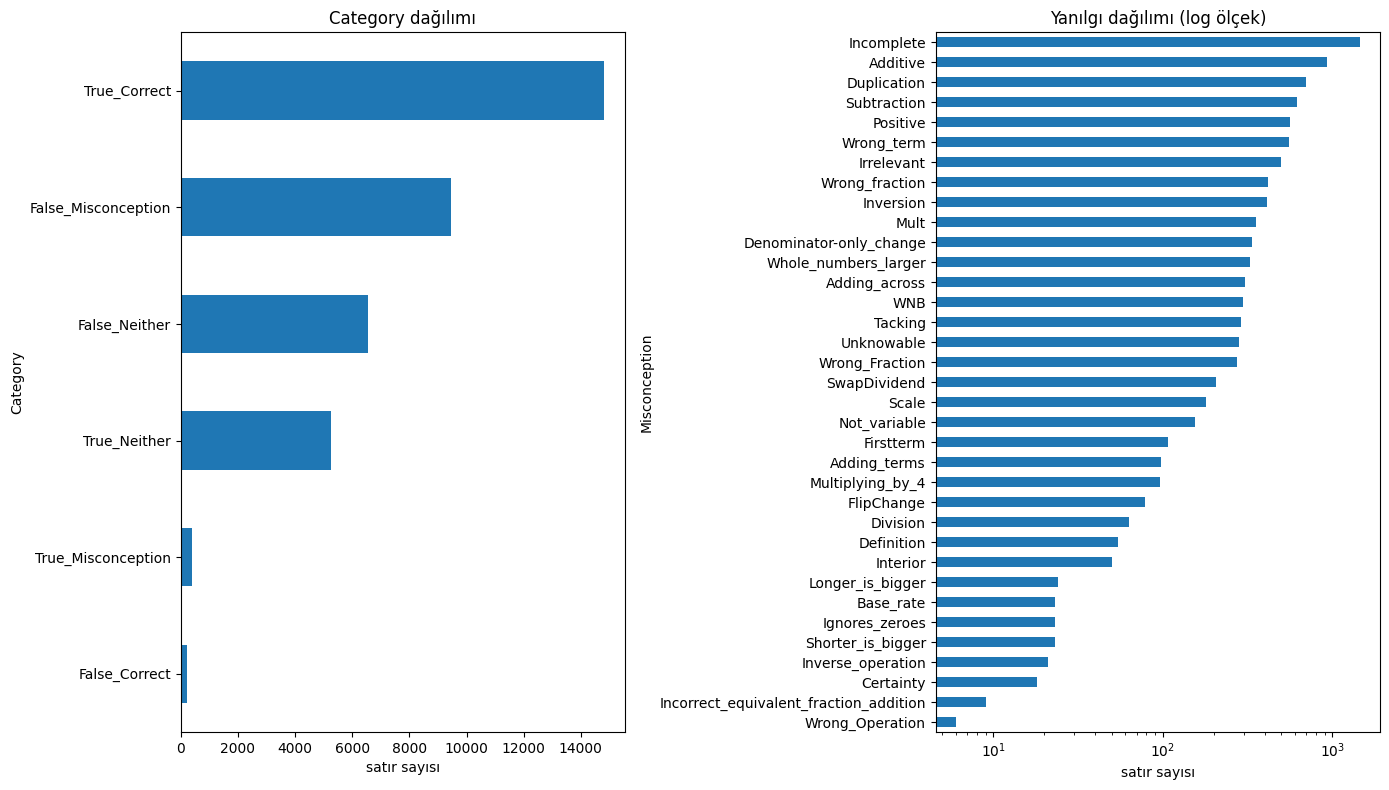

In [33]:
import matplotlib.pyplot as plt

# category sınıflarının satır sayısı ve yüzdesi
cat = train["Category"].value_counts()
print(pd.DataFrame({"satır": cat, "oran (%)": (cat / len(train) * 100).round(1)}))

# modelin tahmin edeceği birleşik etiket: Category:Misconception
train["etiket"] = train["Category"] + ":" + train["Misconception"]
print("\nfarklı etiket sayısı:", train["etiket"].nunique())

# yanılgı dağılımı ("NA" yani yanılgı olmayan satırlar hariç)
yan = train.loc[train["Misconception"] != "NA", "Misconception"].value_counts()
print("farklı yanılgı sayısı:", len(yan))
print("\nen nadir 5 yanılgı:\n", yan.tail(5))

# iki grafik yan yana: solda category, sağda yanılgılar
fig, ax = plt.subplots(1, 2, figsize=(14, 8))
cat.plot.barh(ax=ax[0], title="Category dağılımı")
yan.plot.barh(ax=ax[1], title="Yanılgı dağılımı (log ölçek)", logx=True)
for a in ax:
    a.invert_yaxis()   # en sık görülen en üstte olsun
    a.set_xlabel("satır sayısı")
plt.tight_layout()
plt.show()

### **Bulgu:** Sınıflar dengesiz: True_Correct satırların %40,3'ü, True_Misconception (%1,1) ve False_Correct (%0,6) ise çok nadir. Tahmin edilecek 65 farklı `Category:Misconception` etiketi ve 35 farklı yanılgı var. Yanılgılarda uzun bir kuyruk görülüyor: en sık yanılgı (Incomplete) 1.454, en nadiri (Wrong_Operation) 6 satır (sağdaki grafik log ölçekli). Bu yüzden train/validation bölmesini stratified yapacağız, yoksa nadir etiketler validation'a hiç düşmeyebilir. Nadir etiketlerdeki performansı ise yorumlarken dikkatli olmalıyız, çünkü validation'da birkaç örnekleri olacak.

## **Soru 7: Her soruda kaç satır var, öğrencilerin ne kadarı doğru şıkkı seçmiş?**

            satir  dogru_orani
QuestionId                    
31772        4857         48.3
31778        3640         48.2
31774        3115         61.6
32833        3105         51.6
89443        3054         45.6
31777        2809         64.0
33472        2800         59.0
91695        2610         59.3
32835        2332         71.8
32829        2156         79.6
33474        1766         35.7
33471        1542         56.7
76870        1186         42.8
109465       1051         52.6
104665        673         73.8

en az / en çok satır: 673 / 4857


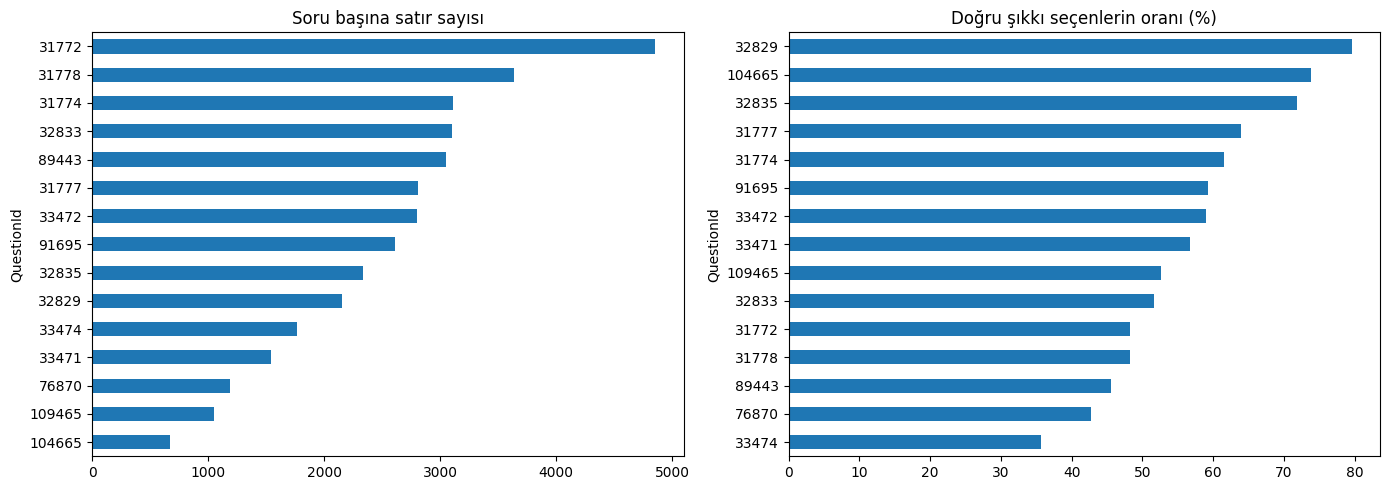

In [34]:
# her soru için: satır sayısı ve doğru şıkkı seçenlerin yüzdesi
soru_ozet = train.groupby("QuestionId").agg(
    satir=("row_id", "size"),
    dogru_orani=("sik_gercekten_dogru", "mean"),
)
soru_ozet["dogru_orani"] = (soru_ozet["dogru_orani"] * 100).round(1)
print(soru_ozet.sort_values("satir", ascending=False))
print("\nen az / en çok satır:", soru_ozet["satir"].min(), "/", soru_ozet["satir"].max())

# satır sayısını ve doğru oranını yan yana çiz
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
soru_ozet["satir"].sort_values().plot.barh(ax=ax[0], title="Soru başına satır sayısı")
soru_ozet["dogru_orani"].sort_values().plot.barh(ax=ax[1], title="Doğru şıkkı seçenlerin oranı (%)")
plt.tight_layout()
plt.show()

### **Bulgu:** Soru başına satır sayısı 673 (104665) ile 4.857 (31772) arasında; en büyük soru en küçüğünün yaklaşık 7 katı. Doğru şıkkı seçenlerin oranı %35,7 (33474) ile %79,6 (32829) arasında değişiyor, yani sorular bu veride farklı zorlukta. Satır sayısı ile doğru oranı arasında belirgin bir ilişki görünmüyor. Sorunun kimliği tek başına True/False için güçlü bir ipucu; soru bazlı bir baseline'ın genel bir baseline'dan daha iyi çalışmasını bekliyoruz. Not: Oranlar sadece bu veri setindeki öğrencilere ait, sorunun genel zorluğunu göstermeyebilir.

##**Soru 8: Toplam kaç farklı Category:Misconception etiketi var?**

In [35]:
#Category ve Misconception etiketlerini birleştir ve
#target isimli yeni etiketi oluştur ve kaç farklı target olduğunu yazdır
train["target"] = train["Category"] + ":" + train["Misconception"]
print("Farklı etiket sayısı:", train["target"].nunique())

#en sık ve en nadir kullanılan 10 etikketten kaçar satır var
etiket_sayilari = train["target"].value_counts()
print("\nEn sık 10 etiket:")
print(etiket_sayilari.head(10))
print("\nEn nadir 10 etiket:")
print(etiket_sayilari.tail(10))

#10'dan az sayıda örneği olan etiket sayısı
print("\n10'dan az örneği olan etiket sayısı:", (etiket_sayilari < 10).sum())

Farklı etiket sayısı: 65

En sık 10 etiket:
target
True_Correct:NA                       14802
False_Neither:NA                       6542
True_Neither:NA                        5265
False_Misconception:Incomplete         1446
False_Misconception:Additive            891
False_Misconception:Duplication         698
False_Misconception:Subtraction         618
False_Misconception:Positive            564
False_Misconception:Wrong_term          550
False_Misconception:Wrong_fraction      412
Name: count, dtype: int64

En nadir 10 etiket:
target
True_Misconception:Multiplying_by_4                          3
True_Misconception:Definition                                3
True_Misconception:Positive                                  2
True_Misconception:Incorrect_equivalent_fraction_addition    2
True_Misconception:Subtraction                               2
True_Misconception:Not_variable                              1
True_Misconception:Whole_numbers_larger                      1
True_Misconcep

###**Bulgu**: Model 65 farklı etiket arasından seçim yapacak. En sık etiket True_Correct:NA (14.802 satır). 24 etiketin 10'dan az örneği var; bunların çoğu True_Misconception ile başlıyor ve bazılarında sadece 1 örnek var. Bu kadar az örnekten öğrenmek çok zor. Bu sebeple modelin bu etiketleri tahmin edememesi çok olası.

##**Soru 9: Her soruda kaç satır var, doğru cevap oranı ne?**

            satir_sayisi  dogru_orani
QuestionId                           
31772               4857         0.48
31778               3640         0.48
31774               3115         0.62
32833               3105         0.52
89443               3054         0.46
31777               2809         0.64
33472               2800         0.59
91695               2610         0.59
32835               2332         0.72
32829               2156         0.80
33474               1766         0.36
33471               1542         0.57
76870               1186         0.43
109465              1051         0.53
104665               673         0.74


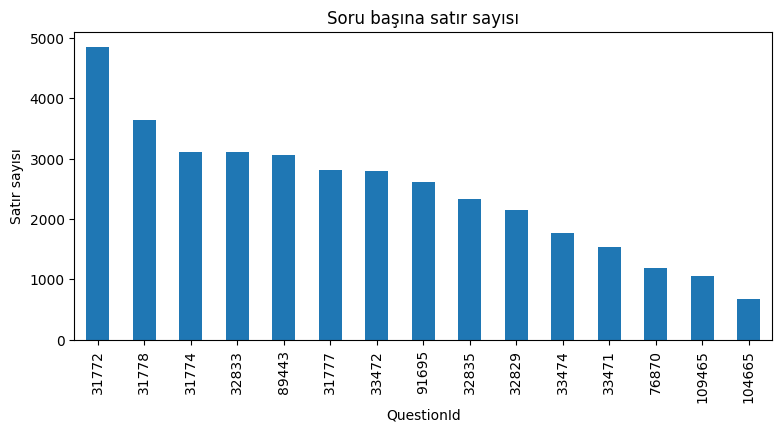

In [36]:
import matplotlib.pyplot as plt

#Category'si "True" ile başlayan satırlarda en sık seçilen şık
true_satirlar = train[train["Category"].str.startswith("True")]
dogru_sik = true_satirlar.groupby("QuestionId")["MC_Answer"].agg(lambda s:
s.value_counts().index[0])
train["is_correct"] = (train["MC_Answer"] == train["QuestionId"].map(dogru_sik)).astype(int)

#Her soru için satır sayısı ve doğru şıkkı seçenlerin oranı
soru_ozeti = train.groupby("QuestionId").agg(
satir_sayisi=("row_id", "size"),
dogru_orani=("is_correct", "mean")
).sort_values("satir_sayisi", ascending=False)
soru_ozeti["dogru_orani"] = soru_ozeti["dogru_orani"].round(2)
print(soru_ozeti)

# Soru başına satır sayısını çubuk grafikle göster
soru_ozeti["satir_sayisi"].plot.bar(figsize=(9, 4), title="Soru başına satır sayısı")
plt.xlabel("QuestionId")
plt.ylabel("Satır sayısı")
plt.show()

###**Bulgu:** Sorular veride eşit dağılmıyor. En büyük soruda (31772) 4.857 satır, en küçükte (104665) 673 satır var. Arada neredeyse 7 kat fark var. Yani model büyük sorulardan, küçük sorulara göre daha çok öğrenecek. Doğru cevap oranı da sorudan soruya çok değişiyor. 33474'te %36, 32829'da %80. Yani bazı sorular öğrenciler için çok daha zorlayıcı.



##**Soru 10: Açıklamalar ne uzunlukta, aşırı kısa ya da uzun olanlar var mı?**

count    36696.0
mean        15.4
std          8.1
min          1.0
25%         10.0
50%         13.0
75%         19.0
max        177.0
Name: kelime_sayisi, dtype: float64


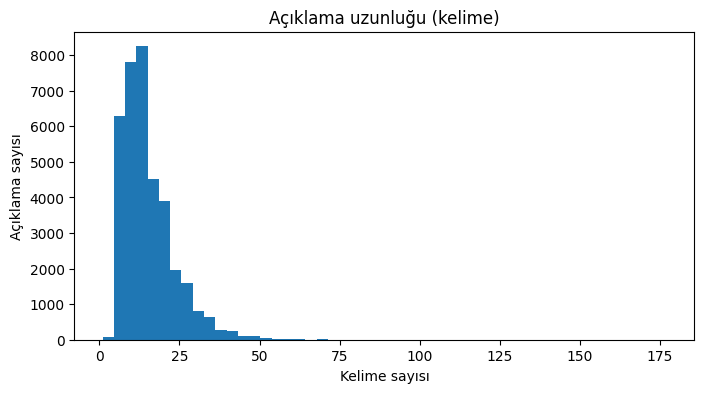


2 kelime veya daha kısa açıklama sayısı: 30
50 kelimeden uzun açıklama sayısı: 121
       StudentExplanation             Category
2960                  3/9        False_Neither
2961                  3/9        False_Neither
7698   1x1=1, 2x6=12:1/12        False_Correct
16575      y=24------->48  False_Misconception
19162                (B).        False_Neither
26929            times by         True_Neither
29045           144x5=720  False_Misconception
29315                 -13        False_Neither
29316                 -13        False_Neither
29317                 -13        False_Neither
Category
False_Neither          14
True_Correct            7
True_Neither            6
False_Misconception     2
False_Correct           1
Name: count, dtype: int64


In [37]:
#Her açıklamanın kelime sayısı
train["kelime_sayisi"] = train["StudentExplanation"].str.split().str.len()
print(train["kelime_sayisi"].describe().round(1))
#Kelime sayılarının dağılımının  gösterimi (histogram)
train["kelime_sayisi"].plot.hist(bins=50, figsize=(8, 4), title="Açıklama uzunluğu (kelime)")
plt.xlabel("Kelime sayısı")
plt.ylabel("Açıklama sayısı")
plt.show()
#Uç değerler (aşırı kısa ve aşırı uzun açıklamalar)
print("\n2 kelime veya daha kısa açıklama sayısı:", (train["kelime_sayisi"] <= 2).sum())
print("50 kelimeden uzun açıklama sayısı:", (train["kelime_sayisi"] > 50).sum())
#Çok kısa olan açıklamalardan 10 adet örnek ve kategorileri
print(train.loc[train["kelime_sayisi"] <= 2, ["StudentExplanation", "Category"]].head(10))
print(train.loc[train["kelime_sayisi"] <= 2, "Category"].value_counts())

### **Bulgu**: Açıklamalar genel olarak kısa. Ortalama 15,4 kelime, medyan 13 kelime ve en uzunu ise 177 kelime. 30 açıklama 2 kelime veya 2 kelimeden de daha kısa. Bunların 20'si "Neither" kategorisinde. Yani kısa açıklamalar genellikle bilgi taşımıyor, sadece tek kelimelik cevaplar. 121 açıklama ise 50 kelimeden uzun. Uç değerler az olduğu için silmiyoruz.
###Çünkü onlar veri hatası değil, gerçek öğrenci cevapları. Test verisinde de benzerleri olacak ve kısa açıklamalar çoğunlukla "Neither" olduğu için aynı zamanda model için bilgi de taşıyor.

## **Soru 11: LaTeX, [Image: ...], kesir gibi özel yapılar var mı?**

In [38]:
#LaTeX Nedir?
# LaTeX, matematiksel ifadeleri yazmak için kullanılan bir dildir.
# Örneğin 1/3 kesri LaTeX'te \frac{1}{3} diye yazılır.
# Ekranda düzgün bir kesir olarak görünür. Ama veride düz metin olarak durur.
# Yani \( \frac{1}{3} \) şeklinde. Model bu işaretleri anlamsız karakterler olarak görebilir.


# şıkların ne kadarı LaTeX biçiminde yazılmış
print("LaTeX biçimindeki şık oranı:", train["MC_Answer"].str.contains(r"\\\(").mean().round(2))
print(train["MC_Answer"].unique()[:10])

# öğrenci açıklamalarında LaTeX var mı
aciklama = train["StudentExplanation"]
print("\nLaTeX içeren açıklama sayısı:", aciklama.str.contains(r"\\\(|\\frac").sum())

# soru metinlerinde görselden metne çevrilmiş kısımlar
sorular = train.drop_duplicates("QuestionId")
print("\n[Image: ...] içeren soru sayısı:", sorular["QuestionText"].str.contains(r"\[Image").sum(), "/", len(sorular))

# açıklamalarda sayı ve kesir işareti
print("\nSayı içeren açıklama oranı:", aciklama.str.contains(r"\d").mean().round(2))
print("'/' içeren açıklama oranı:", aciklama.str.contains("/", regex=False).mean().round(2))

LaTeX biçimindeki şık oranı: 0.96
['\\( \\frac{1}{3} \\)' '\\( \\frac{3}{6} \\)' '\\( \\frac{3}{8} \\)'
 '\\( \\frac{3}{9} \\)' '\\( 3 \\)' '\\( \\frac{1}{12} \\)'
 '\\( \\frac{6}{2} \\)' '\\( 24 \\)' '\\( 48 \\)' '\\( 60 \\)']

LaTeX içeren açıklama sayısı: 0

[Image: ...] içeren soru sayısı: 3 / 15

Sayı içeren açıklama oranı: 0.78
'/' içeren açıklama oranı: 0.27


###**Bulgu:** Şıkların %96'sı LaTeX biçiminde yazılmıştır. öğrencilerin açıklamalarında ise hiç LaTeX yok. Kesirleri "3/9" gibi düz metinle yazmışlar. Yani aynı kesir, şıkta ve açıklamada farklı biçimlerde geçebiliyor.

###15 sorudan 3'ünde görseller "[Image: ...]" şeklinde metne çevrilmiş. Açıklamalarının %78'inde sayı, %27'sinde ise "/" işareti var.

İlerde model için şıklardaki LaTeX işaretlerini temizleyip  açıklamalardaki öğrenci yazımlarıyla aynı hâle getirmek faydalı olabilir.


##**Soru 12: Açıklamalarda yazım hataları ne kadar yaygın?**

In [39]:
# açıklamaları küçük harfe çevirip kelimelere ayır
# sayıları da kelimeye dahil ediyoruz çünkü "6th" gibi ifadeler "th" diye ayrılmamalı
kelimeler = aciklama.str.lower().str.findall(r"[a-z0-9]+").explode()
kelime_sayilari = kelimeler.value_counts()

# sadece harften oluşan kelimelerden en sık geçen 3 tanesi
en_sik = kelime_sayilari[kelime_sayilari.index.str.isalpha()].head(3)
print("En sık geçen 3 kelime:")
print(en_sik)

# bütün yazım hatalarını sayamayız. bu yüzden sadece en sık geçen 3 kelimeyi örnek alıp
# açıklamalara bakarak bulduğumuz yanlış yazılışlarını sayıyoruz
yanlis_yazimlar = {"is": ["ia", "si", "iz"], "the": ["thee", "thr", "th", "teh", "hte", "tge", "rhe", "thw", "tje", "tha"], "because": ["becuase", "beacuse", "becasue", "becaus"]}

# because için kısaltmalar
print("\n'because' kısaltmaları:", {k: int(kelime_sayilari.get(k, 0)) for k in ["bc", "cuz", "coz"]})

# her kelime için doğru ve yanlış yazılış sayılarını tabloya koy
tablo = pd.DataFrame({"kelime": list(yanlis_yazimlar)})
tablo["doğru yazılış"] = tablo["kelime"].map(lambda k: kelime_sayilari.get(k, 0))
tablo["yanlış yazılış"] = tablo["kelime"].map(lambda k: sum(kelime_sayilari.get(y, 0) for y in yanlis_yazimlar[k]))
tablo["yanlış oranı (%)"] = (tablo["yanlış yazılış"] / (tablo["doğru yazılış"] + tablo["yanlış yazılış"]) * 100).round(2)
# en sık 3 yanlış yazılışı örnek olarak göster
tablo["en sık yanlış yazılışlar"] = tablo["kelime"].map(lambda k: ", ".join(f"{y} ({kelime_sayilari.get(y, 0)})" for y in sorted(yanlis_yazimlar[k], key=lambda y: -kelime_sayilari.get(y, 0))[:3]))
tablo


En sık geçen 3 kelime:
StudentExplanation
is         26444
the        25031
because    19088
Name: count, dtype: int64

'because' kısaltmaları: {'bc': 28, 'cuz': 12, 'coz': 5}


,kelime,doğru yazılış,yanlış yazılış,yanlış oranı (%),en sık yanlış yazılışlar
0,is,26444,2,0.01,"ia (1), si (1), iz (0)"
1,the,25031,248,0.98,"thee (162), thr (49), th (28)"
2,because,19088,138,0.72,"becuase (57), beacuse (41), becasue (23)"


**Bulgu:** Sözlük olmadan bütün yazım hatalarını sayamadığımız için en sık geçen 3 kelimeye (is, the, because) olası yanlış yazımlarını elimizle tek tek girerek baktık. "the" kelimesinin %1'e yakını (248 kez), "because" kelimesinin %0,7'si (138 kez") yanlış yazılmış. Ayrıca "because" 45 kez "bc", "cuz", "coz" diye kısaltılmış. "is" ise neredeyse hiç yanlış yazılmamış. Ama iki harfli bir kelimenin yanlış yazılışı çoğu zaman başka gerçek bir kelimeye örneğin"us", "it" dönüşüyor ve bu sebeple ayırt edilemeyebiliyor. Sık kullanılan uzun kelimelerde yazım hatası oranı yaklaşık %1.

İlerde model için metni küçük harfe çevirmek faydalı olur. Yazım hataları aynı kelimeyi farklı kelimeler gibi gösterdiği için, kelimelerin harf parçalarına bakan yöntemler bu hatalardan daha az etkilenir.

##**Soru 13: Her soruda hangi yanılgılar görülüyor?**

In [40]:
# Misconception (kavram yanılgısı): Öğrencinin rastgele yaptığı bir hata değil,
# yanlış öğrenilmiş ve tutarlı şekilde uygulanan bir kural ya da düşünce biçimi.
# Örnek: "0,355 > 0,8.

# sadece misconception içeren satırlar yani NA olmayanlar
yanilgili = train[train["Misconception"] != "NA"]

# her soruda hangi misconception lar ve her birinden kaçar satır var
print(yanilgili.groupby(["QuestionId", "Misconception"]).size())

# her soruda kaç farklı misconception görülüyor
print(yanilgili.groupby("QuestionId")["Misconception"].nunique())

# birden fazla soruda geçen miscoception lar
kac_soruda = yanilgili.groupby("Misconception")["QuestionId"].nunique()
print(kac_soruda[kac_soruda > 1])

QuestionId  Misconception                         
31772       Incomplete                                1359
            WNB                                        262
31774       FlipChange                                  78
            Mult                                       353
            SwapDividend                               206
31777       Incomplete                                  76
            Irrelevant                                  41
            Wrong_Fraction                             273
31778       Additive                                   929
            Irrelevant                                 456
            WNB                                         37
32829       Adding_terms                                97
            Inverse_operation                           21
            Not_variable                               154
32833       Duplication                                704
            Inversion                                  414
     

###**Bulgu:** Her soruda sadece 2–4 farklı yanılgı (misconception) görülüyor. 35 yanılgının neredeyse hepsi tek bir soruya özgü. Sadece 3 yanılgı birden fazla soruda geçiyor. mIncomplete (3 soruda), WNB ve Irrelevant (ikişer soruda). Yani soru bilindiğinde olası yanılgıların sayısı 35'ten 2–4'e iniyor. Yani bu  modelin soru bilgisini mutlaka ve kesinlikle kullanması gerektiğini gösteriyor. Ayrıca Wrong_Fraction (31777) ve Wrong_fraction (33471) farklı sorularda geçiyor. Bu yüzden aynı yanılgı olmayabilirler.